# Baseline: KKR (GL) vs eksperymentalne $T_c$, skład A (Ti, Nb, Zr, Hf, Ta, Mo, W, Y, Re, Ru)

- **Eksperyment:** `results/Tc_literature.xlsx`.
- **KKR:** `results/comparison.sra.ew0.6.bz10-10-20.gl` (wariant GL: wzór powierzchniowy Gaspari–Gyorffy'ego i całkowita
  DOS Lloyda w 1/N(E_F)).
- **θ_D:** reguła mieszaniny, jak w optymalizacji: $\lambda_{\rm mix} = \lambda_{\rm KKR}(\theta_{\rm KKR}/\theta_{\rm mix})^2$,
  potem McMillan.
- **Zbiory pierwiastków:** stop należy do zbioru, jeśli wszystkie jego pierwiastki są w zbiorze.
  - skład A = Ti, Nb, Zr, Hf, Ta, Mo, W, Y, Re, Ru;
  - skład B = Ti, Nb, Zr, Hf, Ta, Mo, W, Y, V, Sc;
  - A ∪ B = stopy należące do A lub do B.

**Poprawka corr2** (`Tc_corr2`, `process_kkr.compute_tc_corrected`, parametry `TC_CORR_*` w `consts.py`, cel optymalizacji
`--target Tc_corr` od 2026-11-02): McMillan z μ\* = 0.1 i dwiema zmianami:
- θ_D fazy bcc dla **Sc** (215 K zamiast 355 K) w regule mieszaniny, λ przeskalowane o $(\theta_{\rm mix}/\theta_{\rm corr})^2$;
- sprzężenie elektron–paramagnon tylko na **V** (Bose 2009): $\lambda_{es} = x_V\,\alpha_V\,s_V\ln\frac{1}{1-s_V}$,
  $s_V = I_V N_V(E_F)$, α_V = 0.4; $T_c = \frac{\theta}{1.45}\exp\left[-\frac{1.04(1+\lambda+\lambda_{es})}{\lambda-\lambda_{es}-\mu^*(1+0.62(\lambda+\lambda_{es}))}\right]$.

Poprawka dotyczy więc tylko stopów zawierających V lub Sc. **Dla składu A `Tc_corr2 == Tc_mu0.1` dokładnie** (sprawdzane
assertem poniżej), a w A ∪ B zmieniają się tylko wiersze z V/Sc.

Porównywane warianty: (`Tc_mu0.1`, `μ* = 0.1`), (`Tc_mu0.2`, `μ* = 0.2`). Notebook nie zapisuje plików graficznych.

In [1]:
import json, pathlib, sys
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openpyxl
from scipy import stats
from IPython.display import display
sys.path.insert(0, '../scripts')
import src.process_kkr as pk
RY_EV = 13.605693123
assert (dict(pk.TC_CORR_THETA_BCC_K), dict(pk.TC_CORR_SF_ALPHA), pk.TC_CORR_MU) == ({'Sc': 215.0}, {'V': 0.4}, 0.1), \
    'consts.py nie odpowiada wersji corr2'

SET = 'A'
VARIANTS = [('Tc_mu0.1', 'μ* = 0.1'), ('Tc_mu0.2', 'μ* = 0.2')]
XLSX    = pathlib.Path('../results/Tc_literature.xlsx')
RESULTS = pathlib.Path('../results/comparison.sra.ew0.6.bz10-10-20.gl')
EXCLUDE = {'NbTa67MoHfW33'}
SET_A = ['Ti', 'Nb', 'Zr', 'Hf', 'Ta', 'Mo', 'W', 'Y', 'Re', 'Ru']
SET_B = ['Ti', 'Nb', 'Zr', 'Hf', 'Ta', 'Mo', 'W', 'Y', 'V', 'Sc']

# kolumny xlsx (arkusz 'Tc_literature'): A nazwa, B–N skład, S Tc_exp, Z autor, AE status
ELEMENTS = ['Sc', 'Ti', 'Y', 'Zr', 'Nb', 'Mo', 'Ru', 'La', 'Hf', 'Ta', 'W', 'Re', 'V']
COL_NAME, COL_EL0, COL_TC_EXP, COL_AUTHOR, COL_STATUS = 1, 2, 19, 26, 31
COMP_TOL = 2e-3
MARKER = {'single-phase bcc': 'o', 'caution (multiphase etc.)': '^'}
pd.set_option('display.max_rows', 200, 'display.width', 250)

Using AKAIMODBIN: /home/rafal/WORK/HEA/RKKY/cpa2002v010.potential2026/specx


## 0. Dane: eksperyment + KKR (dopasowanie po składzie)

In [2]:
def _val(cell):
    try:
        return float(cell.value)
    except (TypeError, ValueError):
        return np.nan

kkr = {}
for d in sorted(RESULTS.iterdir()):
    p = d / 'results.json'
    if p.is_file():
        j = json.loads(p.read_text())
        x = np.array([float(j.get(e) or 0.0) for e in ELEMENTS])
        kkr[d.name] = (x / x.sum(), j)

def mcmillan(theta, lam, mu):
    denom = lam - mu * (1 + 0.62 * lam)
    return theta / 1.45 * np.exp(-1.04 * (1 + lam) / denom) if denom > 0 else 0.0

ws = openpyxl.load_workbook(XLSX, data_only=True)['Tc_literature']
rows, unmatched = [], []
for r in range(4, ws.max_row + 1):
    name, tc = ws.cell(r, COL_NAME).value, _val(ws.cell(r, COL_TC_EXP))
    x = np.nan_to_num([_val(ws.cell(r, COL_EL0 + i)) for i in range(len(ELEMENTS))])
    if not name or np.isnan(tc) or x.sum() == 0 or name in EXCLUDE:
        continue
    x = x / x.sum()
    k = min(kkr, key=lambda k: np.abs(kkr[k][0] - x).max())
    if np.abs(kkr[k][0] - x).max() > COMP_TOL:
        unmatched.append(name); continue
    j = kkr[k][1]
    els = {e for e, xi in zip(ELEMENTS, x) if xi > 0}
    comp = dict(zip(ELEMENTS, x))
    lam_mix = j['lambda'] * (j['thetaDB_K'] / j['mixture_debye_temperature']) ** 2
    # Tc_corr2: funkcja produkcyjna, na danych w postaci jak w optymalizacji (θ_mix, λ_mix, debye_mode 'mix')
    c = pk.compute_tc_corrected({'thetaDB': j['mixture_debye_temperature'], 'lambda': lam_mix, 'debye_mode': 'mix',
                                 **{f'{e}_Ntot': j.get(f'{e}_Ntot') for e in ELEMENTS}},
                                dict(zip(ELEMENTS, kkr[k][0])))     # skład KKR (θ_mix w results.json liczone z niego)
    status = ws.cell(r, COL_STATUS).value or ''
    rows.append(dict(name=name, author=ws.cell(r, COL_AUTHOR).value or '', kkr_dir=k, Tc_exp=tc,
                     group='caution (multiphase etc.)' if status.startswith('caution') else 'single-phase bcc',
                     in_A=els <= set(SET_A), in_B=els <= set(SET_B), has_VSc=bool(els & {'V', 'Sc'}), **comp,
                     theta_mix=j['mixture_debye_temperature'], lambda_mix=lam_mix,
                     **{'Tc_mu0.1': mcmillan(j['mixture_debye_temperature'], lam_mix, 0.1),
                        'Tc_mu0.2': mcmillan(j['mixture_debye_temperature'], lam_mix, 0.2),
                        'Tc_corr2': c['Tc_corr']},
                     theta_corr=c['theta_corr'], lambda_corr=c['lambda_corr'], lambda_es=c['lambda_es']))
ALL = pd.DataFrame(rows)

# corr2 nie zmienia niczego bez V i Sc
noVSc = ~ALL.has_VSc
assert np.allclose(ALL.loc[noVSc, 'Tc_corr2'], ALL.loc[noVSc, 'Tc_mu0.1'], atol=1e-12, rtol=0)
print(f"Tc_corr2 == Tc_mu0.1 dla wszystkich {noVSc.sum()} wierszy bez V i Sc (w tym całego składu A: {ALL.in_A.sum()})")

DF = {'A': ALL[ALL.in_A], 'B': ALL[ALL.in_B], 'AB': ALL[ALL.in_A | ALL.in_B]}[SET].reset_index(drop=True)
ELSET = {'A': SET_A, 'B': SET_B, 'AB': sorted(set(SET_A) | set(SET_B), key=ELEMENTS.index)}[SET]
print(f"wiersze z Tc_exp i wynikiem KKR (wszystkie): {len(ALL)} (bez wyniku KKR: {unmatched or 'brak'})")
print(f"zbiór {SET}: {len(DF)} wierszy ({(DF.group != 'single-phase bcc').sum()} 'caution'), {DF.kkr_dir.nunique()} składów KKR, "
      f"z V: {(DF.V > 0).sum()}, ze Sc: {(DF.Sc > 0).sum()}, z Re/Ru: {((DF.Re > 0) | (DF.Ru > 0)).sum()}")

Tc_corr2 == Tc_mu0.1 dla wszystkich 74 wierszy bez V i Sc (w tym całego składu A: 74)
wiersze z Tc_exp i wynikiem KKR (wszystkie): 121 (bez wyniku KKR: brak)
zbiór A: 74 wierszy (9 'caution'), 65 składów KKR, z V: 0, ze Sc: 0, z Re/Ru: 9


**Metryki:**
- **kolejność** (najważniejsza dla optymalizacji): Kendall τ, Spearman ρ oraz odsetek par źle uporządkowanych spośród par,
  których eksperymentalne Tc różnią się o ponad 1 K;
- **dopasowanie liniowe** $T_c^{\rm exp} = a\,T_c^{\rm KKR} + b$ (R², Pearson r) oraz prosta przez zero $T_c^{\rm exp} = s\,T_c^{\rm KKR}$;
- **wartości bezwzględne:** MAE, bias (średnia KKR − exp) i mediana stosunku KKR/exp.

In [3]:
def misordered(x, y, dT=1.0):
    good = bad = 0
    for i, j in combinations(range(len(y)), 2):
        if abs(y[i] - y[j]) > dT:
            s = np.sign(y[i] - y[j]) * np.sign(x[i] - x[j])
            good += s > 0; bad += s < 0
    return bad / (good + bad) if good + bad else np.nan

def metrics(x, y):
    lr = stats.linregress(x, y)
    return {'n': len(y), 'Kendall τ': stats.kendalltau(x, y)[0], 'Spearman ρ': stats.spearmanr(x, y)[0],
            'źle uporządk. pary (ΔTc>1K)': misordered(x, y),
            'Pearson r': lr.rvalue, 'R² (LR)': lr.rvalue ** 2, 'a (LR)': lr.slope, 'b (LR) [K]': lr.intercept,
            's (LR przez 0)': np.sum(x * y) / np.sum(x * x),
            'MAE [K]': np.mean(np.abs(x - y)), 'bias [K]': np.mean(x - y), 'mediana KKR/exp': np.median(x / y)}


def summary_table(subsets):
    return pd.DataFrame([{'podzbiór': sn, 'wariant': col, **metrics(s[col].values, s.Tc_exp.values)}
                         for sn, s in subsets.items() if len(s) > 2 for col, _ in VARIANTS]
                        ).set_index(['podzbiór', 'wariant']).round(3)


def linear_plot(df, fit_mask=None, fit_label='wszystkie punkty'):
    # fit_mask: wiersze użyte do dopasowania i metryk; na wykresie zawsze wszystkie punkty
    fit = df if fit_mask is None else df[fit_mask]
    cols = [c for c, _ in VARIANTS]
    lim = (0, max(df.Tc_exp.max(), df[cols].values.max()) * 1.05)
    fig, axes = plt.subplots(1, len(VARIANTS), figsize=(7 * len(VARIANTS), 6.2), sharey=True)
    for ax, (col, lab) in zip(axes, VARIANTS):
        m = metrics(fit[col].values, fit.Tc_exp.values)
        for grp, g in df.groupby('group'):
            for vsc, gg in g.groupby('has_VSc'):
                ax.scatter(gg[col], gg.Tc_exp, marker=MARKER[grp], s=50, edgecolors='k', linewidths=0.4, zorder=3,
                           color='C1' if vsc else 'C0', label=f"{grp}{', z V/Sc' if vsc else ''} (n={len(gg)})")
        xl = np.linspace(*lim, 100)
        ax.plot(xl, xl, ':', color='gray', label='y = x')
        ax.plot(xl, m['a (LR)'] * xl + m['b (LR) [K]'], color='C3', lw=1.8,
                label=f"LR: y = {m['a (LR)']:.2f}x {m['b (LR) [K]']:+.2f}")
        ax.plot(xl, m['s (LR przez 0)'] * xl, '--', color='C2', lw=1.4, label=f"LR przez 0: y = {m['s (LR przez 0)']:.2f}x")
        ax.text(0.03, 0.97, f"dopasowanie i metryki: {fit_label} (n={len(fit)})\n"
                            f"Kendall τ = {m['Kendall τ']:.3f}\nSpearman ρ = {m['Spearman ρ']:.3f}\n"
                            f"Pearson r = {m['Pearson r']:.3f}\nR² = {m['R² (LR)']:.3f}\n"
                            f"MAE = {m['MAE [K]']:.2f} K\nbias = {m['bias [K]']:+.2f} K",
                transform=ax.transAxes, va='top', fontsize=10, bbox=dict(boxstyle='round', fc='white', ec='#cccccc', alpha=0.9))
        ax.set(xlim=lim, ylim=lim, xlabel=f'KKR {col} [K]', title=lab)
        ax.grid(alpha=0.3); ax.legend(fontsize=8, loc='lower right')
    axes[0].set_ylabel('eksperymentalne $T_c$ [K]')
    fig.suptitle(f'Baseline, zbiór {SET} (n={len(df)} na wykresie, dopasowanie: {fit_label}), KKR GL, θ_D mix '
                 f'(pomarańczowe = stopy z V lub Sc)', fontsize=13)
    plt.tight_layout(); plt.show()


def element_panels(df, col, lab):
    present = [e for e in ELSET if (df[e] > 0).any()]
    ncol = 4; nrow = int(np.ceil(len(present) / ncol))
    lim = (0, max(df[col].max(), df.Tc_exp.max()) * 1.05)
    fig, axes = plt.subplots(nrow, ncol, figsize=(4.4 * ncol, 3.9 * nrow), sharex=True, sharey=True, squeeze=False)
    for ax, el in zip(axes.flat, present):
        has = df[el] > 0
        ax.scatter(df.loc[~has, col], df.loc[~has, 'Tc_exp'], s=16, color='#d9d9d9', zorder=2)
        vmax = df.loc[has, el].max()
        for grp, g in df[has].groupby('group'):
            ax.scatter(g[col], g.Tc_exp, c=g[el], cmap='viridis', vmin=0, vmax=vmax, marker=MARKER[grp],
                       s=40, edgecolors='k', linewidths=0.3, zorder=3)
        ax.plot(lim, lim, ':', color='gray')
        cb = fig.colorbar(plt.cm.ScalarMappable(norm=plt.Normalize(0, vmax), cmap='viridis'), ax=ax, fraction=0.046, pad=0.02)
        cb.set_label(f'$x_{{\\rm {el}}}$')
        ax.set(xlim=lim, ylim=lim, title=f'{el} (n={has.sum()})')
    for ax in axes.flat[len(present):]:
        ax.set_visible(False)
    for ax in axes[-1]:
        ax.set_xlabel(f'KKR {col} [K]')
    for ax in axes[:, 0]:
        ax.set_ylabel('eksp. $T_c$ [K]')
    fig.suptitle(f'Zbiór {SET}: eksperyment vs KKR ({lab}), kolor = udział pierwiastka, ● single-phase ▲ caution', fontsize=12)
    plt.tight_layout(); plt.show()


def ordering_plot(df):
    fig, axes = plt.subplots(1, len(VARIANTS) + 1, figsize=(6.3 * (len(VARIANTS) + 1), 5.6))
    n = len(df)
    rk_exp = df.Tc_exp.rank(ascending=False)
    for ax, (col, lab) in zip(axes, VARIANTS):
        rk_kkr = df[col].rank(ascending=False)
        for grp, g in df.groupby('group'):
            ax.scatter(rk_kkr[g.index], rk_exp[g.index], marker=MARKER[grp], s=40, edgecolors='k', linewidths=0.3, label=grp)
        ax.plot([1, n], [1, n], ':', color='gray')
        ax.set(xlabel='ranga KKR', ylabel='ranga eksperymentalna', xlim=(0, n + 1), ylim=(0, n + 1),
               title=f"{lab}:  Spearman ρ = {stats.spearmanr(rk_kkr, rk_exp)[0]:.3f}")
        ax.invert_xaxis(); ax.invert_yaxis(); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc='lower left')
    DTS = np.arange(0, 4.01, 0.25)
    y = df.Tc_exp.values
    for col, lab in VARIANTS:
        x = df[col].values
        axes[-1].plot(DTS, [1 - misordered(x, y, dT) for dT in DTS], marker='o', label=lab)
    axes[-1].set(xlabel='próg |ΔTc_exp| [K]', ylabel='odsetek par dobrze uporządkowanych',
                 title='Poprawna kolejność par vs różnica Tc', ylim=(0.5, 1.0))
    axes[-1].grid(alpha=0.3); axes[-1].legend()
    plt.tight_layout(); plt.show()
    (c1, _), (c2, _) = VARIANTS
    print(f"Kendall τ między rankingami KKR {c1} i {c2}: {stats.kendalltau(df[c1], df[c2])[0]:.3f}")


def alloy_table(df):
    cols = [c for c, _ in VARIANTS]
    extra = ['theta_corr', 'lambda_es'] if 'Tc_corr2' in cols else []
    tab = df[['name', 'author', 'group', 'Tc_exp', 'theta_mix', 'lambda_mix', *extra, *cols]].copy()
    for c in cols:
        tab[f'KKR/exp {c}'] = tab[c] / tab.Tc_exp
    return tab.sort_values('Tc_exp', ascending=False).reset_index(drop=True).round(3)

## 1. Metryki

In [4]:
SUBSETS = {'skład A, wszystkie': DF, 'tylko single-phase bcc': DF[DF.group == 'single-phase bcc'],
    'z Re/Ru': DF[(DF.Re > 0) | (DF.Ru > 0)], 'bez Re/Ru (wspólne z B)': DF[(DF.Re == 0) & (DF.Ru == 0)],
    'z Ti ≥ 20 %': DF[DF.Ti >= 0.2]}
summary_table(SUBSETS)

n  Kendall τ  Spearman ρ  źle uporządk. pary (ΔTc>1K)  Pearson r  R² (LR)  a (LR)  b (LR) [K]  s (LR przez 0)  MAE [K]  bias [K]  mediana KKR/exp
podzbiór                wariant                                                                                                                                                     
skład A, wszystkie      Tc_mu0.1  74      0.659       0.855                        0.064      0.843    0.711   0.454       3.382           0.876    1.399     0.331            1.053
                        Tc_mu0.2  74      0.645       0.847                        0.063      0.806    0.650   0.765       4.844           2.199    4.344    -4.344            0.303
tylko single-phase bcc  Tc_mu0.1  65      0.694       0.875                        0.050      0.867    0.751   0.464       3.390           0.887    1.370     0.313            1.061
                        Tc_mu0.2  65      0.674       0.864                        0.050      0.836    0.699   0.796       4.867           2.277    4.425    -4.425            0.323
z Re/Ru                 Tc_mu0.1   9      0.085       0.176                        0.450      0.502    0.252   0.229       3.612           0.949    1.375    -0.385            0.888
                        Tc_mu0.2   9      0.028       0.159                        0.450      0.552    0.304   0.594       4.123           3.194    3.816    -3.816            0.105
bez Re/Ru (wspólne z B) Tc_mu0.1  65      0.667       0.846                        0.046      0.840    0.706   0.431       3.650           0.872    1.402     0.431            1.061
                        Tc_mu0.2  65      0.645       0.833                        0.048      0.795    0.631   0.701       5.110           2.178    4.417    -4.417            0.324
z Ti ≥ 20 %             Tc_mu0.1  33      0.609       0.791                        0.131      0.813    0.660   0.576       2.955           1.066    1.211    -0.796            0.869
                        Tc_mu0.2  33      0.628       0.804                        0.122      0.829    0.687   1.310       4.419           3.544    4.768    -4.768            0.163

## 2. KKR vs eksperyment, dopasowanie liniowe

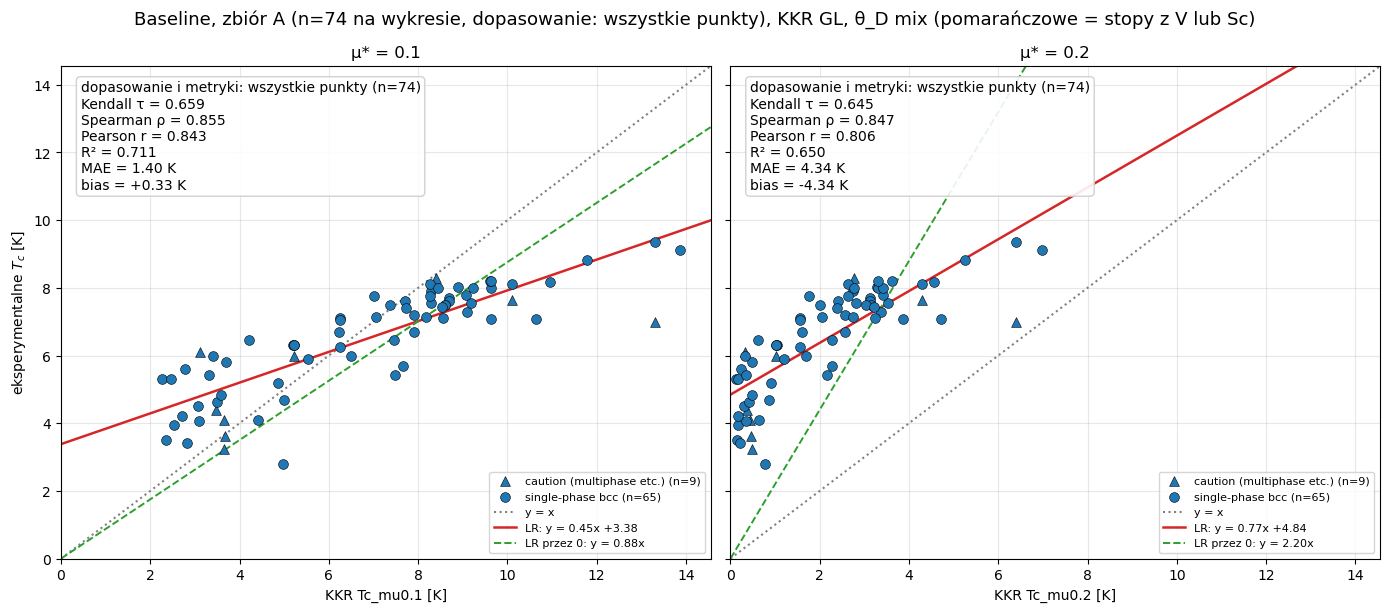

In [5]:
linear_plot(DF)

## 3. Wykresy kolorowane udziałem pierwiastka

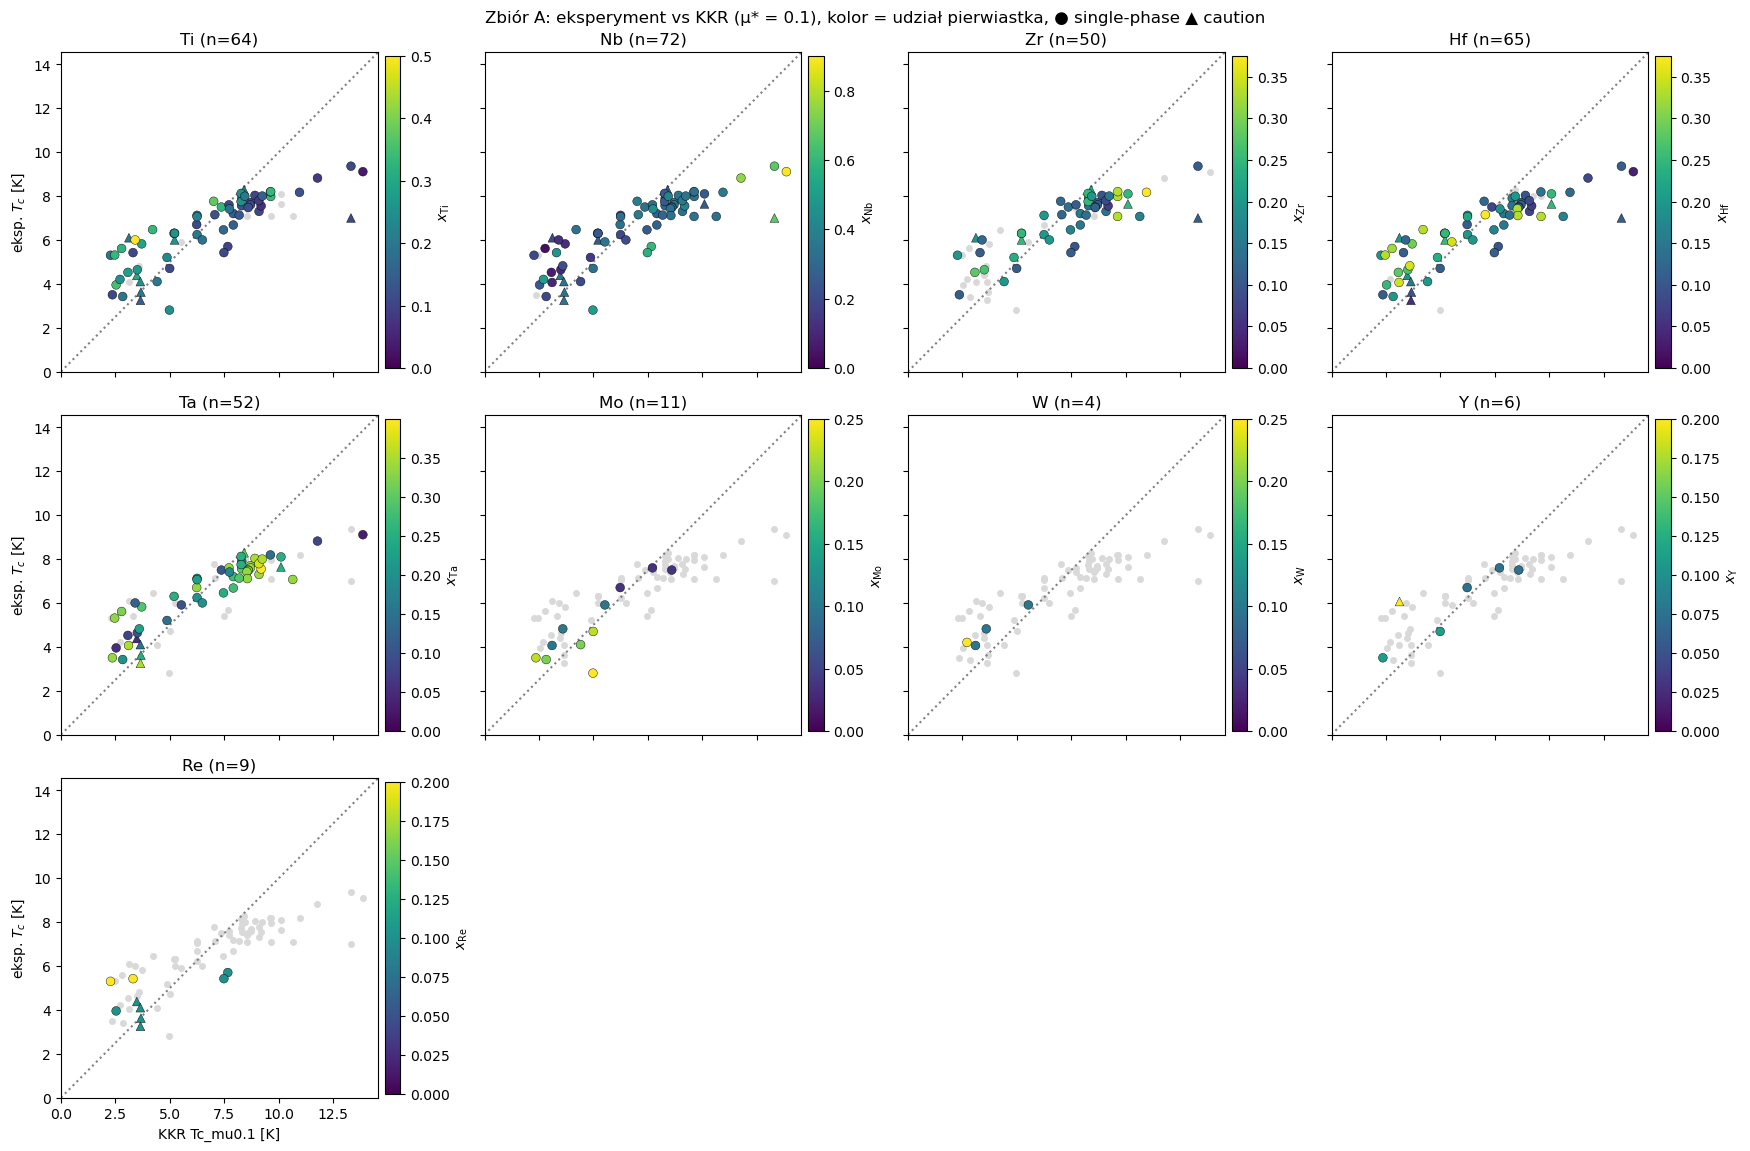

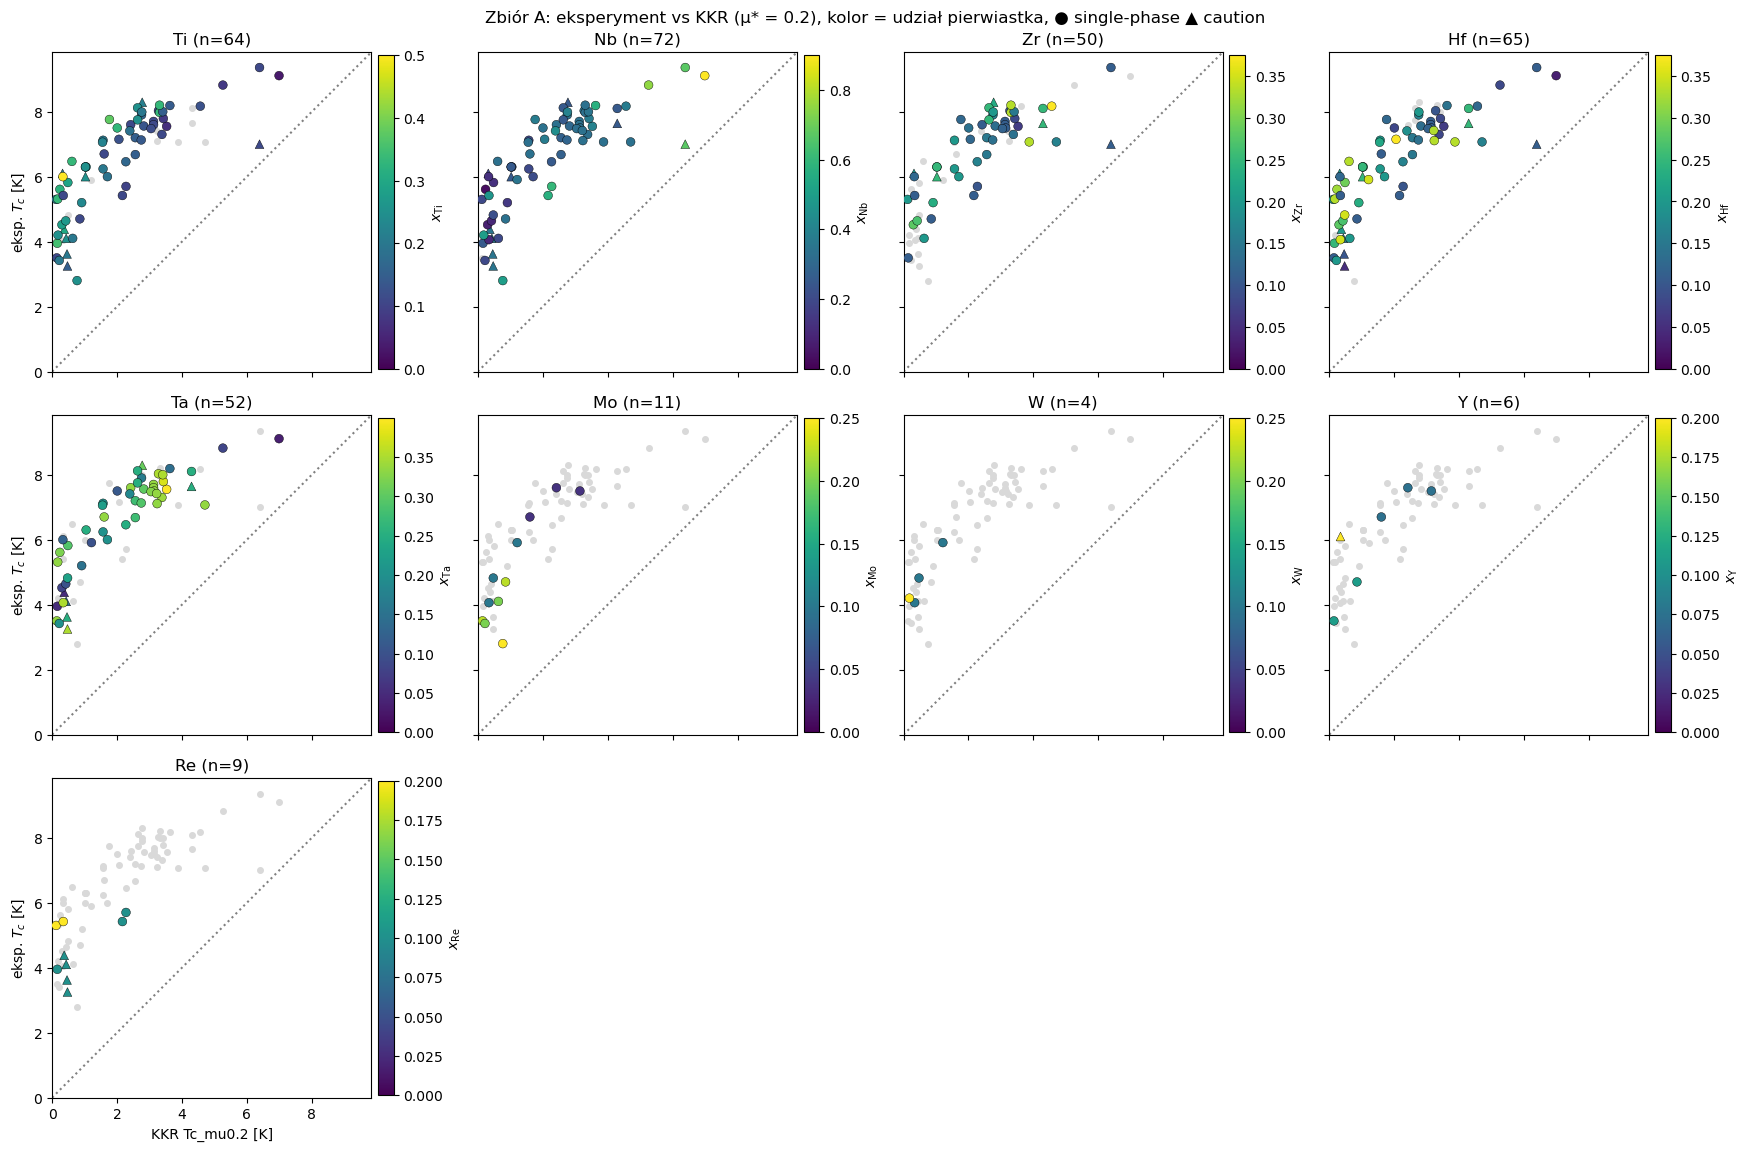

In [6]:
for col, lab in VARIANTS:
    element_panels(DF, col, lab)

## 4. Zachowanie kolejności

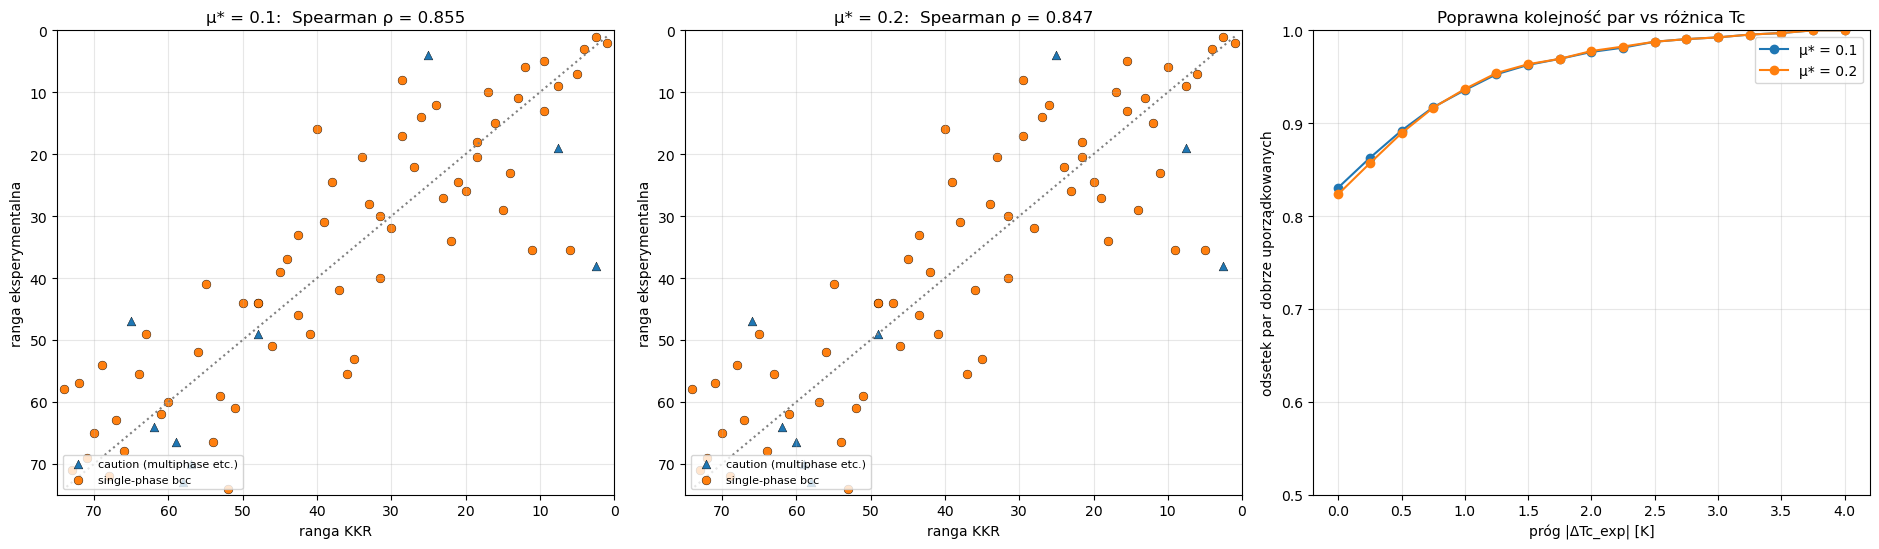

Kendall τ między rankingami KKR Tc_mu0.1 i Tc_mu0.2: 0.961


In [7]:
ordering_plot(DF)

## 5. Tabela stopów (posortowana po Tc_exp)

In [8]:
alloy_table(DF)

,name,author,group,Tc_exp,theta_mix,lambda_mix,Tc_mu0.1,Tc_mu0.2,KKR/exp Tc_mu0.1,KKR/exp Tc_mu0.2
0,Nb67HfZrTi33,von Rohr,single-phase bcc,9.36,287.650,0.877,13.311,6.389,1.422,0.683
1,(TiHfTa)1-xNbx_x0.9,Li,single-phase bcc,9.11,277.833,0.915,13.858,6.990,1.521,0.767
2,(TiHfTa)1-xNbx_x0.75,Li,single-phase bcc,8.82,282.083,0.830,11.775,5.260,1.335,0.596
3,NbTaTiZr_Wu2018,Wu,caution (multiphase etc.),8.29,294.000,0.698,8.405,2.775,1.014,0.335
4,TiZrNb_Kosuth,Košuth,single-phase bcc,8.20,321.667,0.711,9.628,3.308,1.174,0.403
5,(TiHfTa)1-xNbx_x0.57,Li,single-phase bcc,8.19,287.183,0.747,9.612,3.627,1.174,0.443
6,NbZr75TiHf25,Idczak,single-phase bcc,8.17,288.125,0.792,10.949,4.564,1.340,0.559
7,TaNbZrTi_Krishnan,Krishnan,single-phase bcc,8.12,301.250,0.687,8.268,2.632,1.018,0.324
8,TaNbHfZr_Wu2024,Wu,single-phase bcc,8.10,258.750,0.802,10.098,4.294,1.247,0.530
9,TaNb70ZrHfTi30,von Rohr,single-phase bcc,8.03,274.250,0.737,8.902,3.276,1.109,0.408


## Wnioski (2026-11-05)

- **corr2 nie ma wpływu na skład A:** `Tc_corr2 == Tc_mu0.1` dla wszystkich 74 wierszy (assert w sekcji 0). Ten notebook
  jest więc jednocześnie porównaniem dla celu `Tc_corr` na składzie A.
- **μ\* = 0.1:** τ 0.66 (single-phase 0.69), r 0.84, MAE 1.40 K, mediana KKR/exp 1.05; źle uporządkowanych 6 % par
  różniących się o ponad 1 K.
- **μ\* = 0.2** daje prawie tę samą kolejność (τ 0.65), ale zaniża Tc ok. 3× (mediana 0.30, MAE 4.3 K).
- **Re/Ru** (n = 9): τ 0.09, za mało punktów do wniosków.
- **Ti ≥ 20 %** (n = 33): τ 0.61, Tc lekko zaniżone (mediana 0.87).
- Wyniki są identyczne z sekcją 1 starszego notebooka `Tc_Baseline_Comparison.ipynb`.